# PEFT: Parameter-Efficient Fine-Tuning

[LoRA](/how-models-work/lora-low-rank-adaptation/) is the best-known way to
adapt a large model without training all of it, but it is one of a family.
Every member makes the same trade. Freeze the pre-trained weights, add or
unfreeze a small set of parameters, and train only those. They differ in
**where** the new parameters go:

| Method | Paper | What is trained |
|---|---|---|
| Adapters | Houlsby et al., 2019 | small bottleneck MLPs inserted after sub-layers |
| BitFit | Ben Zaken et al., 2022 | only the bias terms |
| Prefix tuning | Li & Liang, 2021 | learned key/value vectors prepended in every layer |
| Prompt tuning | Lester et al., 2021 | learned input embeddings prepended to the input only |
| LoRA | Hu et al., 2021 | low-rank updates to weight matrices |
| (IA)³ | Liu et al., 2022 | vectors that rescale keys, values and FFN activations |

This page implements all six, plus head-only and full fine-tuning, inside one
small transformer. Each method adapts the same pre-trained model to the same new
task, and the page measures how many parameters each trains and how well each
does. It also counts what each would cost on a 7B-parameter model.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from hmw_motion import Scene, mix

torch.manual_seed(0); np.random.seed(0)
torch.set_num_threads(4)


def banner(title):
    print("=" * 78); print(f"  {title}"); print("=" * 78)


def step(label):
    print(); print(label); print("-" * 78)


def check(label, ok):
    print(f"  [{'PASS' if ok else 'FAIL'}] {label}")
    return ok


print("helpers ready")

helpers ready


## 1. One transformer with every insertion point

The model treats an 8×8 handwritten digit as a sequence of **8 tokens**, one
per pixel row, plus a `[CLS]` token whose final state is classified. It has two
transformer blocks, $d = 48$, and 4 heads.

The block below is an ordinary pre-LN transformer block. The only unusual thing
is that it carries the hooks each PEFT method needs, and every hook is off by
default.

In [2]:
D, H, FF, P = 48, 4, 96, 6           # width, heads, FFN width, # virtual tokens


class Block(nn.Module):
    def __init__(self):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(D), nn.LayerNorm(D)
        self.q, self.k, self.v, self.o = (nn.Linear(D, D) for _ in range(4))
        self.f1, self.f2 = nn.Linear(D, FF), nn.Linear(FF, D)
        self.peft = {}                                   # method name -> modules

    def add(self, method, r=4, m=8):
        if method == "lora":
            for name in ("q", "v"):
                A = nn.Parameter(torch.randn(r, D) / D ** .5); B = nn.Parameter(torch.zeros(D, r))
                self.register_parameter(f"lora_A_{name}", A); self.register_parameter(f"lora_B_{name}", B)
        elif method == "adapter":
            for name in ("attn", "ffn"):
                dn, up = nn.Linear(D, m), nn.Linear(m, D)
                nn.init.zeros_(up.weight); nn.init.zeros_(up.bias)    # starts as identity
                self.add_module(f"adapter_down_{name}", dn); self.add_module(f"adapter_up_{name}", up)
        elif method == "prefix":
            self.prefix_k = nn.Parameter(torch.randn(P, D) * 0.1)
            self.prefix_v = nn.Parameter(torch.randn(P, D) * 0.1)
        elif method == "ia3":
            self.ia3_k, self.ia3_v = nn.Parameter(torch.ones(D)), nn.Parameter(torch.ones(D))
            self.ia3_ff = nn.Parameter(torch.ones(FF))
        self.peft[method] = True

    def proj(self, name, x):
        out = getattr(self, name)(x)
        if "lora" in self.peft and name in ("q", "v"):
            out = out + x @ getattr(self, f"lora_A_{name}").T @ getattr(self, f"lora_B_{name}").T
        return out

    def adapter(self, name, x):
        if "adapter" not in self.peft:
            return x
        return x + getattr(self, f"adapter_up_{name}")(F.relu(getattr(self, f"adapter_down_{name}")(x)))

    def forward(self, x):
        B_, T, _ = x.shape
        h = self.ln1(x)
        q, k, v = self.proj("q", h), self.proj("k", h), self.proj("v", h)
        if "ia3" in self.peft:
            k, v = k * self.ia3_k, v * self.ia3_v
        if "prefix" in self.peft:
            k = torch.cat([self.prefix_k.expand(B_, P, D), k], 1)
            v = torch.cat([self.prefix_v.expand(B_, P, D), v], 1)
        split = lambda t: t.view(B_, -1, H, D // H).transpose(1, 2)
        att = (split(q) @ split(k).transpose(-2, -1) / (D // H) ** .5).softmax(-1)
        y = (att @ split(v)).transpose(1, 2).reshape(B_, T, D)
        x = x + self.adapter("attn", self.o(y))
        a = F.gelu(self.f1(self.ln2(x)))
        if "ia3" in self.peft:
            a = a * self.ia3_ff
        return x + self.adapter("ffn", self.f2(a))


class Net(nn.Module):
    def __init__(self, n_out=5):
        super().__init__()
        self.inp = nn.Linear(8, D)
        self.cls = nn.Parameter(torch.zeros(1, 1, D))
        self.pos = nn.Parameter(torch.randn(1, 9, D) * 0.02)
        self.blocks = nn.ModuleList([Block(), Block()])
        self.ln = nn.LayerNorm(D)
        self.head = nn.Linear(D, n_out)
        self.prompt = None

    def forward(self, img):
        x = self.inp(img.view(-1, 8, 8))
        x = torch.cat([self.cls.expand(len(x), 1, D), x], 1) + self.pos
        if self.prompt is not None:                       # prompt tuning: extra input tokens
            x = torch.cat([x[:, :1], self.prompt.expand(len(x), P, D), x[:, 1:]], 1)
        for b in self.blocks:
            x = b(x)
        return self.head(self.ln(x[:, 0]))


net = Net()
print(f"  backbone parameters: {sum(p.numel() for n_, p in net.named_parameters() if not n_.startswith('head')):,}")

  backbone parameters: 38,928


## 2. Pre-train, then adapt to classes it has never seen

The backbone is pre-trained on digits 0 to 4. The new task is digits 5 to 9,
with only 150 labelled images. Every method gets a fresh 5-way head, and
otherwise trains only its own parameters.

In [3]:
banner("PRE-TRAINING ON DIGITS 0-4")
dg = load_digits()
X = torch.tensor(dg.data / 16.0, dtype=torch.float32); y = torch.tensor(dg.target)
Xp, yp = X[y < 5], y[y < 5]
Xn_tr, Xn_te, yn_tr, yn_te = train_test_split(X[y >= 5], y[y >= 5] - 5, test_size=0.5, random_state=0,
                                              stratify=y[y >= 5])
Xn_tr, yn_tr = Xn_tr[:150], yn_tr[:150]
torch.manual_seed(0)
opt = torch.optim.AdamW(net.parameters(), lr=3e-3)
for it in range(800):
    idx = torch.randint(0, len(Xp), (128,))
    loss = F.cross_entropy(net(Xp[idx]), yp[idx])
    opt.zero_grad(); loss.backward(); opt.step()
net.eval()
print(f"  accuracy on 0-4 (train): {(net(Xp).argmax(1) == yp).float().mean():.3f}")
pretrained = {k: v.clone() for k, v in net.state_dict().items()}

  PRE-TRAINING ON DIGITS 0-4
  accuracy on 0-4 (train): 1.000


  EIGHT WAYS TO ADAPT
  head only          new non-head params      0 ( 0.00% of backbone)   accuracy 0.835 ± 0.002
  prompt tuning      new non-head params    288 ( 0.74% of backbone)   accuracy 0.842 ± 0.020
  prefix tuning      new non-head params  1,152 ( 2.96% of backbone)   accuracy 0.872 ± 0.005
  (IA)^3             new non-head params    384 ( 0.99% of backbone)   accuracy 0.923 ± 0.009
  BitFit             new non-head params    960 ( 2.47% of backbone)   accuracy 0.879 ± 0.008
  LoRA r=4 (q, v)    new non-head params  1,536 ( 3.95% of backbone)   accuracy 0.911 ± 0.009
  adapters (m=8)     new non-head params  3,296 ( 8.47% of backbone)   accuracy 0.899 ± 0.007
  full fine-tune     new non-head params 38,928 (100.00% of backbone)   accuracy 0.943 ± 0.001

Checks
------------------------------------------------------------------------------
  [PASS] LoRA, adapters and (IA)^3 start as exact no-ops (identical outputs before training)
  [PASS] every PEFT method beats training the

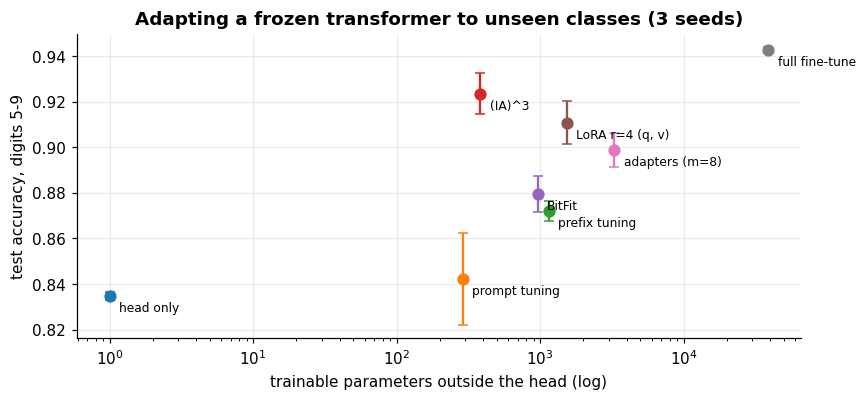

In [4]:
banner("EIGHT WAYS TO ADAPT")


def adapted(method, seed):
    torch.manual_seed(seed)
    m = Net(); m.load_state_dict(pretrained)
    m.head = nn.Linear(D, 5)
    for p in m.parameters():
        p.requires_grad = method == "full"
    if method == "prompt":
        m.prompt = nn.Parameter(torch.randn(1, P, D) * 0.1)
    elif method in ("lora", "adapter", "prefix", "ia3"):
        for b in m.blocks:
            b.add(method)
    elif method == "bitfit":
        for n_, p in m.named_parameters():
            if n_.endswith("bias"):
                p.requires_grad = True
    for p in m.head.parameters():
        p.requires_grad = True
    if m.prompt is not None:
        m.prompt.requires_grad = True
    return m


def n_trainable(m, include_head=True):
    return sum(p.numel() for n_, p in m.named_parameters()
               if p.requires_grad and (include_head or not n_.startswith("head")))


def finetune(method, seed, steps=500):
    m = adapted(method, seed)
    params = [p for p in m.parameters() if p.requires_grad]
    lr = 3e-2 if method in ("prompt", "prefix") else 3e-3      # soft prompts need a larger step
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.0)
    g = torch.Generator().manual_seed(seed)
    for it in range(steps):
        idx = torch.randint(0, len(Xn_tr), (64,), generator=g)
        loss = F.cross_entropy(m(Xn_tr[idx]), yn_tr[idx])
        opt.zero_grad(); loss.backward(); opt.step()
    m.eval()
    with torch.no_grad():
        return (m(Xn_te).argmax(1) == yn_te).float().mean().item(), m


methods = ["head", "prompt", "prefix", "ia3", "bitfit", "lora", "adapter", "full"]
names = {"head": "head only", "prompt": "prompt tuning", "prefix": "prefix tuning", "ia3": "(IA)^3",
         "bitfit": "BitFit", "lora": "LoRA r=4 (q, v)", "adapter": "adapters (m=8)", "full": "full fine-tune"}
total_backbone = sum(p.numel() for n_, p in net.named_parameters() if not n_.startswith("head"))
res = {}
for meth in methods:
    accs, mods = [], []
    for s in range(3):
        a, m = finetune(meth, s)
        accs.append(a); mods.append(m)
    nt = n_trainable(mods[0], include_head=False)
    res[meth] = (np.mean(accs), np.std(accs), nt)
    print(f"  {names[meth]:<18} new non-head params {nt:>6,} ({100*nt/total_backbone:5.2f}% of backbone)"
          f"   accuracy {np.mean(accs):.3f} ± {np.std(accs):.3f}")

step("Checks")
zero_init_ok = True
for meth in ["lora", "adapter", "ia3"]:
    m = adapted(meth, 0); m.head.load_state_dict(adapted("head", 0).head.state_dict())
    ref = adapted("head", 0)
    with torch.no_grad():
        zero_init_ok &= torch.allclose(m(Xn_te), ref(Xn_te), atol=1e-6)
check("LoRA, adapters and (IA)^3 start as exact no-ops (identical outputs before training)", zero_init_ok)
check("every PEFT method beats training the head alone",
      all(res[mm][0] > res["head"][0] for mm in ["lora", "adapter", "ia3", "bitfit"]))

fig, ax = plt.subplots(figsize=(8.5, 3.6))
for meth in methods:
    a, s_, nt = res[meth]
    ax.errorbar(max(nt, 1), a, yerr=s_, fmt="o", ms=7, capsize=3)
    ax.annotate(names[meth], (max(nt, 1), a), textcoords="offset points", xytext=(6, -10), fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("trainable parameters outside the head (log)")
ax.set_ylabel("test accuracy, digits 5-9"); ax.set_title("Adapting a frozen transformer to unseen classes (3 seeds)")

## 3. Reading the results

* **Head only** leaves the backbone's features exactly as they were. They were
  learned for 0 to 4, so they are the floor.
* **Prompt tuning** trains the fewest parameters, six input vectors. On a small
  model it is the weakest PEFT method. Lester et al. found the gap closes only
  as models grow, and above about 10B parameters prompt tuning matches full
  fine-tuning.
* **Prefix tuning** reaches every layer, not just the input, and does better.
* **BitFit, (IA)³, LoRA and adapters** change how the backbone transforms its
  input, inside every block. Measured against the gap between head-only and full
  fine-tuning, they recover between about 40% (BitFit) and 80% ((IA)³) of it.
  (IA)³ does best here with only 384 trainable numbers.

The exact ranking on a toy problem should not be taken too seriously. The
pattern that recurs at every scale is that methods which touch every layer beat
methods which only touch the input.

## 4. What each costs on a 7B model

At scale the counts matter more than the toy accuracies. For a
Llama-2-7B-shaped model ($d = 4096$, 32 layers, FFN width 11,008, 6.74B
parameters):

In [5]:
banner("TRAINABLE PARAMETERS ON A 7B-SHAPED MODEL")
d, L, ff, V = 4096, 32, 11008, 32000
full7 = 2 * V * d + L * (4 * d * d + 3 * d * ff + 2 * d) + d
rows = [
    ("prompt tuning (20 tokens)", 20 * d),
    ("(IA)^3 (k, v, ffn)", L * (2 * d + ff)),
    ("LoRA r=8 on q, v", L * 2 * 8 * (d + d)),
    ("prefix tuning (20 per layer)", L * 2 * 20 * d),
    ("LoRA r=8, all 7 linear layers", L * (4 * 8 * (d + d) + 3 * 8 * (d + ff))),
    ("adapters (2 per layer, m=64)", L * 2 * (d * 64 + 64 + 64 * d + d)),
    ("full fine-tuning", full7),
]
print(f"  total parameters: {full7:,} ({full7/1e9:.2f}B)\n")
for name, n in rows:
    print(f"  {name:<32} {n:>15,}   {100*n/full7:9.5f}%   fp16 file {n*2/1e6:>10,.1f} MB")
print("\n  BitFit is not listed: Llama-style models have no bias terms to train.")
seven = dict(rows)

  TRAINABLE PARAMETERS ON A 7B-SHAPED MODEL
  total parameters: 6,738,415,616 (6.74B)

  prompt tuning (20 tokens)                 81,920     0.00122%   fp16 file        0.2 MB
  (IA)^3 (k, v, ffn)                       614,400     0.00912%   fp16 file        1.2 MB
  LoRA r=8 on q, v                       4,194,304     0.06224%   fp16 file        8.4 MB
  prefix tuning (20 per layer)           5,242,880     0.07781%   fp16 file       10.5 MB
  LoRA r=8, all 7 linear layers         19,988,480     0.29663%   fp16 file       40.0 MB
  adapters (2 per layer, m=64)          33,820,672     0.50191%   fp16 file       67.6 MB
  full fine-tuning                   6,738,415,616   100.00000%   fp16 file   13,476.8 MB

  BitFit is not listed: Llama-style models have no bias terms to train.


The same block, with each method's parameters dropped in where they live. The
counts are for the 7B-shaped model.

In [6]:
def peft_scene():
    sc = Scene(720, 430, dur=17.0, caption="Where each PEFT method puts its trainable parameters",
               poster=16.0)
    # block diagram
    X0 = 60
    sc.rect(X0, 40, 330, 330, fill="panel", stroke="grid", sw=1.5, rx=12)
    sc.text(X0 + 165, 54, "transformer block (x 32, frozen)", size=12, fill="muted")
    # input tokens
    toks = [sc.rect(X0 + 70 + i * 34, 392, 28, 24, fill=mix("panel", "blue", .5), stroke="blue", sw=1, rx=4)
            for i in range(6)]
    sc.text(X0 + 300, 404, "input tokens", size=11, fill="muted", anchor="start")
    sc.arrow(X0 + 165, 388, X0 + 165, 340, stroke="muted", sw=2, head=8)
    # attention box with q k v o
    sc.rect(X0 + 30, 205, 270, 130, fill="bg", stroke="cyan", sw=1.5, rx=8)
    sc.text(X0 + 165, 222, "self-attention", size=12, fill="cyan")
    sub = {}
    for i, nm in enumerate(["Wq", "Wk", "Wv", "Wo"]):
        sub[nm] = (X0 + 48 + i * 64, 260)
        sc.rect(X0 + 48 + i * 64, 260, 46, 50, fill="panel", stroke="grid", sw=1, rx=5)
        sc.text(X0 + 71 + i * 64, 285, nm, size=13, mono=True)
    sc.arrow(X0 + 165, 203, X0 + 165, 190, stroke="muted", sw=2, head=7)
    sc.rect(X0 + 30, 90, 270, 98, fill="bg", stroke="violet", sw=1.5, rx=8)
    sc.text(X0 + 165, 108, "feed-forward", size=12, fill="violet")
    for i, nm in enumerate(["up", "act", "down"]):
        sc.rect(X0 + 58 + i * 76, 124, 62, 46, fill="panel", stroke="grid", sw=1, rx=5)
        sc.text(X0 + 89 + i * 76, 147, nm, size=13, mono=True)

    # right-hand readout
    RX = 430
    title = sc.text(RX, 80, "", size=19, fill="text", anchor="start", weight=700)
    what = sc.text(RX, 112, "", size=12, fill="muted", anchor="start")
    cnt = sc.num(RX, 170, 0, dec=0, size=30, fill="amber", anchor="start", sep=True)
    sc.text(RX, 200, "trainable parameters at 7B scale", size=11, fill="muted", anchor="start")
    pct = sc.num(RX, 236, 0, dec=4, post=" % of the model", size=15, fill="green", anchor="start")

    steps_ = [
        ("Prompt tuning", "20 learned vectors prepended to the input", seven["prompt tuning (20 tokens)"], "amber"),
        ("Prefix tuning", "learned keys and values in every layer", seven["prefix tuning (20 per layer)"], "pink"),
        ("(IA)³", "rescale keys, values and FFN activations", seven["(IA)^3 (k, v, ffn)"], "violet"),
        ("LoRA (r = 8, q and v)", "low-rank B A beside the projections", seven["LoRA r=8 on q, v"], "cyan"),
        ("Adapters (m = 64)", "bottleneck MLPs after each sub-layer", seven["adapters (2 per layer, m=64)"], "green"),
    ]
    t = 0.6
    shown = []
    for k, (nm, desc, n, col) in enumerate(steps_):
        for el in shown:
            el.to(t - 0.2, t, opacity=0.18)
        shown = []
        title.set(t, s=nm, fill=col); what.set(t, s=desc)
        cnt.to(t, t + 1.2, v=n, ease="out"); pct.to(t, t + 1.2, v=100 * n / full7, ease="out")
        if k == 0:
            for i in range(3):
                b = sc.rect(X0 + 70 - 34 * (i + 1) - 30, 392, 28, 24, fill=mix("panel", col, .6), stroke=col, sw=1.5,
                            rx=4, opacity=0)
                b.to(t + 0.1 * i, t + 0.5 + 0.1 * i, opacity=1, x=X0 + 70 - 34 * (i + 1), ease="back")
                shown.append(b)
        elif k == 1:
            for nm_ in ["Wk", "Wv"]:
                x_, y_ = sub[nm_]
                for j in range(3):
                    b = sc.rect(x_ + 4 + j * 13, y_ - 30, 11, 22, fill=mix("panel", col, .7), stroke=col, sw=1, rx=2,
                                opacity=0)
                    b.to(t + 0.1 * j, t + 0.5 + 0.1 * j, opacity=1, y=y_ - 18, ease="back")
                    shown.append(b)
        elif k == 2:
            for (x_, y_, w_) in [(sub["Wk"][0], 314, 46), (sub["Wv"][0], 314, 46), (X0 + 134, 174, 62)]:
                b = sc.rect(x_, y_, 0, 6, fill=col, rx=2, opacity=0)
                b.to(t, t + 0.6, w=w_, opacity=1, ease="out"); shown.append(b)
        elif k == 3:
            for nm_ in ["Wq", "Wv"]:
                x_, y_ = sub[nm_]
                bb = sc.rect(x_ + 50, y_ - 2, 8, 26, fill=mix("panel", col, .7), stroke=col, sw=1, rx=2, opacity=0)
                aa = sc.rect(x_ + 50, y_ + 28, 8, 24, fill=mix("panel", col, .7), stroke=col, sw=1, rx=2, opacity=0)
                bb.to(t, t + 0.5, opacity=1); aa.to(t + 0.15, t + 0.65, opacity=1)
                shown += [bb, aa]
        elif k == 4:
            for y_ in [196, 76]:                     # after attention, after the FFN
                b = sc.rect(X0 + 165, y_ - 10, 0, 20, fill=mix("panel", col, .6), stroke=col, sw=1.5, rx=5, opacity=0)
                b.to(t, t + 0.6, x=X0 + 125, w=80, opacity=1, ease="back")
                lab = sc.text(X0 + 165, y_, "adapter", size=10, fill="text", opacity=0)
                lab.fade_in(t + 0.4)
                shown += [b, lab]
        t += 3.0
    sc.beat(0.0, "The frozen block: attention (q, k, v, o projections), then a feed-forward layer.")
    sc.beat(0.6, "Prompt tuning only adds input vectors. It is the cheapest, and it needs a very large model.")
    sc.beat(3.6, "Prefix tuning gives every layer extra keys and values to attend to.")
    sc.beat(6.6, "(IA)³ learns one scaling number per channel: the smallest method that reaches inside.")
    sc.beat(9.6, "LoRA adds a low-rank update beside chosen weight matrices, and can be merged away.")
    sc.beat(12.6, "Adapters insert tiny MLPs in series. Expressive, but they add inference latency.")
    return sc

peft_scene()

<motion scene: Where each PEFT method puts its trainable parameters (54 elements, 17s)>

## 5. Choosing between them

| | Trainable share (7B) | Extra inference cost | Notes |
|---|---|---|---|
| Prompt tuning | ~0.001% | longer input | weak below ~10B parameters |
| Prefix tuning | ~0.08% | longer K/V | unstable to train; usually reparameterised by an MLP |
| (IA)³ | ~0.01% | none once merged into weights | strong for few-shot |
| LoRA | 0.06% (q, v) – 0.3% (all) | **none** once merged | the default today |
| Adapters | ~0.5% | extra layers in series | the original PEFT method |
| BitFit | ~0.1% (models with biases) | none | Llama-style models have no biases |

LoRA became the default because it adds nothing at inference time, works at
any scale, and stacks with 4-bit quantisation (QLoRA). The Hugging Face `peft`
library implements all of the methods above behind one interface.

## Summary

* Every PEFT method freezes the pre-trained model and trains a small set of
  parameters. They differ in where those parameters go: input (prompt), every
  layer's keys and values (prefix), per-channel scales ((IA)³), biases
  (BitFit), weight updates (LoRA), or new modules (adapters).
* On the same frozen transformer, every method beat training the head alone.
  Methods that act inside every block recovered 40–80% of the gap to full
  fine-tuning with 1–8% of its parameters. Prompt tuning, which acts only at the
  input, was the weakest at this size.
* LoRA, adapters and (IA)³ start as exact no-ops, so step 0 is the pre-trained
  model. This was verified.
* At 7B scale, the trainable share ranges from about 0.001% (prompt tuning) to
  about 0.5% (adapters).